Jonas Kaluza
# Comparative Crime Analysis: Chicago vs. Los Angeles (2024)

## Research Question
Welche zeitlichen und tatortbezogenen Muster lassen sich bei Gewalt- und Eigentumsdelikten in Chicago und Los Angeles im Jahr 2024 erkennen?

## Hypothesis
Es wird erwartet, dass Tatzeit und Tatort systematisch zusammenhängen. Insbesondere wird angenommen, dass sich die Zeit-Ort-Muster zwischen Gewalt- und Eigentumsdelikten unterscheiden und dass sich einzelne Assoziationen zwischen Chicago und Los Angeles in ihrer stärke unterschieden.

## Approach
Die Analyse umfasst:
- Datenbereinigung und Harmonisierung beider Datensätze
- Vergleich der Deliktkategorien
- Untersuchung von Tatzeit und Tatort
- Assoziationsanalyse
- Vergleich zwischen Chicago und Los Angeles sowie zwischen Violent und Property Crime

In [1]:
#install required libraries
%pip install pandas matplotlib
%pip install mlxtend

#import libraries
import pandas as pd
import matplotlib.pyplot as plt

#import functions required for association rules
from mlxtend.frequent_patterns import apriori, association_rules

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Data Understanding

### Los Angeles

In diesem Abschnitt wird der Los Angeles Kriminaldatensatz zunächst
eingelesen und auf seine Struktur untersucht.

In [2]:
#load LA crime data set
la = pd.read_csv("lapd_nibrs.csv", sep=";", low_memory=False)

#display of dataset's dimensions
print(la.shape)

#show all columns of dataset's first rows
pd.set_option("display.max_columns", None)
la.head()

(1312614, 44)


,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,Mocodes,Vict Age,Vict Sex,Vict Descent,Premis Cd,Premis Desc,Weapon Used Cd,Weapon Desc,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON,CaseNo,UniqueNIBRNo,TotalOffenseCount,Group,NIBR Code,NIBR Description,Crime Against,TotalVictimCount,Victim Shot,Domestic Violence Crime,Hate Crime,Gang-related Crime,Transit-related Crime,Homeless-Victim Crime,Homeless-Suspect Crime,Homeless-Arrestee Crime
0,211507896.0,04/11/2021 12:00:00 AM,11/07/2020 12:00:00 AM,845,15,N Hollywood,1502,2.0,354.0,THEFT OF IDENTITY,0377,31.0,M,H,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,201516622.0,10/21/2020 12:00:00 AM,10/18/2020 12:00:00 AM,1845,15,N Hollywood,1521,1.0,230.0,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",0416 0334 2004 1822 1414 0305 0319 0400,32.0,M,H,102.0,SIDEWALK,200.0,KNIFE WITH BLADE 6INCHES OR LESS,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,240913563.0,12/10/2024 12:00:00 AM,10/30/2020 12:00:00 AM,1240,9,Van Nuys,933,2.0,354.0,THEFT OF IDENTITY,0377,30.0,M,W,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,210704711.0,12/24/2020 12:00:00 AM,12/24/2020 12:00:00 AM,1310,7,Wilshire,782,1.0,331.0,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,0344,47.0,F,A,101.0,STREET,NaN,NaN,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,201418201.0,10/03/2020 12:00:00 AM,09/29/2020 12:00:00 AM,1830,14,Pacific,1454,1.0,420.0,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),1300 0344 1606 2032,63.0,M,H,103.0,ALLEY,NaN,NaN,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
#get column names
print(la.columns.tolist())

#show data types and Non-Null Count
la.info()

['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT', 'LON', 'CaseNo', 'UniqueNIBRNo', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'TotalVictimCount', 'Victim Shot', 'Domestic Violence Crime', 'Hate Crime', 'Gang-related Crime', 'Transit-related Crime', 'Homeless-Victim Crime', 'Homeless-Suspect Crime', 'Homeless-Arrestee Crime']
<class 'pandas.DataFrame'>
RangeIndex: 1312614 entries, 0 to 1312613
Data columns (total 44 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   DR_NO                    1004894 non-null  float64
 1   Date Rptd                1312614 non-null  str    
 2   DATE OCC       

##  Data Preparation and Cleaning

### Los Angeles

In [4]:
#convert date occurance to datetime format
la["DATE OCC"] = pd.to_datetime(
    la["DATE OCC"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

print(la["DATE OCC"].dtype)

#filtering dataset to crimes in 2024
la_2024 = la[la["DATE OCC"].dt.year == 2024].copy()

#verifying it's the correct data
print(la_2024.shape)
print("first case:", la_2024["DATE OCC"].min())
print("last case:", la_2024["DATE OCC"].max())
print("years:", la_2024["DATE OCC"].dt.year.unique())

datetime64[us]
(212168, 44)
first case: 2024-01-01 00:00:00
last case: 2024-12-31 23:59:00
years: [2024]


In [5]:
#analyzing missing values
missing_la = pd.DataFrame({
    "missing_count": la_2024.isnull().sum(),
    "missing_percent": la_2024.isnull().mean() * 100
}).sort_values("missing_percent", ascending=False)

missing_la

,missing_count,missing_percent
Crm Cd 4,212166,99.999057
Crm Cd 3,212029,99.934486
Crm Cd 2,207098,97.610384
Cross Street,196429,92.581822
Weapon Used Cd,151372,71.345349
Weapon Desc,151372,71.345349
Group,129012,60.806531
Crime Against,128434,60.534105
NIBR Code,127573,60.128295
TotalOffenseCount,127567,60.125467


### Missing Values of Relevant Attributes

### Los Angeles

Wie wir sehen fehlen einige Werte im Datensatz, allerdings sind nicht alle fehlenden Werte wichtig für unsere Analyse. Wichtig sind:

- "DATE OCC" als Datum der Tat
- "TIME OCC" als Tatzeit
- "Crm Cd Desc" und "NIBR Description" als Beschreibungen der Tat
- "Premis Desc" Beschreibung des Tatorts

"DATE OCC" sowie "TIME OCC" liegen lückenlos vor, um "Crm Cd Desc" und "NIBR Description" sowie "Premis Desc" wird es nun gehen.


### Crime Description Variables

Der Los Angeles Datensatz enthält zwei unterschiedliche Staftatsbeschreibenungsspalten. Im folgenden wird geprüft, ob sich "Crm Cd Desc" und "NIBR Description" gegenseitig ergänzen.

In [6]:
#check whether both descriptions complement each other
print("Crm Cd Desc available:", la_2024["Crm Cd Desc"].notna().sum())
print("NIBR available:", la_2024["NIBR Description"].notna().sum())
print("both missing:", (la_2024["Crm Cd Desc"].isna() & la_2024["NIBR Description"].isna()).sum())
print("both available:", (la_2024["Crm Cd Desc"].notna() & la_2024["NIBR Description"].notna()).sum())

crm_sum = la_2024["Crm Cd Desc"].notna().sum()
nibr_sum = la_2024["NIBR Description"].notna().sum()
print(crm_sum + nibr_sum)

Crm Cd Desc available: 127567
NIBR available: 84601
both missing: 0
both available: 0
212168


In [7]:
#combine both description columns to one
la_2024["crime_desc"] = la_2024["Crm Cd Desc"].fillna(la_2024["NIBR Description"])

#test for missing values
print("amount of missing values:", la_2024["crime_desc"].isna().sum() )

print(la_2024.shape)

print(la_2024["crime_desc"].head(30))

#display 30 most frequent descirptions
print(la_2024["crime_desc"].value_counts().head(30))


amount of missing values: 0
(212168, 45)
877327      THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)
877328                             BATTERY - SIMPLE ASSAULT
877329      THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)
877330                             BATTERY - SIMPLE ASSAULT
877331                                BURGLARY FROM VEHICLE
877332                                        OTHER ASSAULT
877333                                BURGLARY FROM VEHICLE
877334                                             BURGLARY
877335                                          TRESPASSING
877336    VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...
877337                             BATTERY - SIMPLE ASSAULT
877338                                     VEHICLE - STOLEN
877339                                     VEHICLE - STOLEN
877340                   THEFT PLAIN - PETTY ($950 & UNDER)
877341                                     VEHICLE - STOLEN
877342                                             BURGLARY

In [8]:
print("amount of different descriptions:", la_2024["crime_desc"].nunique())

la_2024["crime_desc"].value_counts().head(100)

amount of different descriptions: 1469


crime_desc
VEHICLE - STOLEN                                                                        21510
BURGLARY FROM VEHICLE                                                                    9525
SHOPLIFTING - PETTY THEFT ($950 & UNDER)                                                 9056
THEFT PLAIN - PETTY ($950 & UNDER)                                                       8818
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)                                  7945
                                                                                        ...  
273.5(F)(2) - PC - F - Corporal Injury Spouse W/Prior Battery - Simple Assault - 13B      233
422(A) - PC - M - Threaten Crime With Intent To Terrorize -  Intimidation - 13C           233
484(A) - PC - M - Petty Theft -  Theft From Building - 23D                                229
594(B)(1) - PC - M - Vandalism ($400 Or More) - 290                                       228
484(A) - PC - F - Grand Theft - Theft From Motor 

In [9]:
#remove duplicates

print("Amount of duplicates", la_2024.duplicated().sum())

duplicates = la_2024 [la_2024.duplicated(keep=False)]

duplicates

la_2024 = la_2024.drop_duplicates().copy()
print("Duplicates:", la_2024.duplicated().sum())
print("new shape:", la_2024.shape)

print("same DR_NO:",la_2024.loc[la_2024["DR_NO"].notna(), "DR_NO"].duplicated().sum())

print("Same UniqueNIBRNo:",la_2024.loc[la_2024["UniqueNIBRNo"].notna(), "UniqueNIBRNo"].duplicated().sum())

Amount of duplicates 1
Duplicates: 0
new shape: (212167, 45)
same DR_NO: 0
Same UniqueNIBRNo: 0


In [10]:
#check for missing values

important_columns = [
    "DATE OCC",
    "TIME OCC",
    "crime_desc",
    "Premis Desc"
]

print(la_2024[important_columns].isna().sum())

DATE OCC        0
TIME OCC        0
crime_desc      0
Premis Desc    55
dtype: int64


In [11]:
#replace missing values

la_2024["Premis Desc"] = la_2024["Premis Desc"].fillna("UNKNOWN")
print("missing values after cleaning", la_2024["Premis Desc"].isna().sum())

missing values after cleaning 0


### Crime Category Harmonization

Die ursprünglichen Tatbeschreibungen im Datensatz von Los Angeles enthalten viele unterschiedliche Bezeichnungen. Um die Daten mit dem Chicago-Datensatz vergleichbar zu machen, werden die Delikte in drei Kategorien eingeteilt:

VIOLENT
PROPERTY
OTHER

Die Einteilung basiert auf zuvor definierten Schlüsselwörtern.

In [12]:
#building categories (I got to these after some tests and updates)

violent_words = [
    "ROBBERY",
    "ASSAULT",
    "BATTERY",
    "HOMICIDE",
    "RAPE",
    "CRIMINAL THREAT",
    "THREATEN CRIME",
    "BRANDISH",
    "ADW",
    "ATTEMPT MURDER",
    "CHILD ABUSE",
    "DEADLY WEAPON OTHER THAN FIREARM - AGGRAVATED"
]

property_words = [
    "THEFT",
    "BURGLARY",
    "STOLEN",
    "SHOPLIFTING",
    "VANDALISM",
    "PICKPOCKET",
    "ARSON",
    "FORGERY",
    "FALSE PRETENSES",
    "EXTORTION"
]

both = la_2024[
    la_2024["crime_desc"].apply(
        lambda x:
        any(word in x.upper() for word in violent_words)
        and
        any(word in x.upper() for word in property_words)
    )
]

print("Descriptions that include keywords from different categories:", len(both))

neither = la_2024[
    la_2024["crime_desc"].apply(
        lambda x:
        not any(word in x.upper() for word in violent_words)
        and
        not any(word in x.upper() for word in property_words)
    )
]

print("Descriptions without any keyword:", len(neither))


Descriptions that include keywords from different categories: 0
Descriptions without any keyword: 21811


In [13]:
#Categorization of descriptions

def categorize_crime(description):
    description = description.upper()

    if any(word in description for word in violent_words):
        return "VIOLENT"

    elif any(word in description for word in property_words):
        return "PROPERTY"

    else:
        return "OTHER"


la_2024["crime_category"] = la_2024["crime_desc"].apply(categorize_crime)

la_2024["crime_category"].value_counts()

la_2024["crime_category"].value_counts(normalize=True) * 100

crime_category
PROPERTY    61.975236
VIOLENT     27.744654
OTHER       10.280110
Name: proportion, dtype: float64

In [14]:
#most common premis descriptions

la_2024["Premis Desc"].value_counts().head(30)

Premis Desc
STREET                                          39932
Street/Parkway                                  14771
SINGLE FAMILY DWELLING                          14425
Residence / Home / Driveway                     12070
MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)    11019
PARKING LOT                                      8315
Apartment/Condo Common Laundry Room              6726
OTHER BUSINESS                                   6167
Sidewalk                                         5713
Parking Lot / Garage / Drop Lot                  5165
Victim's Residence                               5005
Other Business                                   4177
VEHICLE, PASSENGER/TRUCK                         3521
DEPARTMENT STORE                                 3488
SIDEWALK                                         3449
Single Family Home                               2928
GARAGE/CARPORT                                   2347
DRIVEWAY                                         1967
Highway / Road /

In [15]:
#capitalizing all letters in premises
la_2024["premis_clean"] = (
    la_2024["Premis Desc"]
    .str.strip()
    .str.upper()
)

#building categories (I got to these after a lot of testing and updates)
residential_words = [
    "RESIDENCE",
    "RESIDENTIAL",
    "HOME",
    "DWELLING",
    "APARTMENT",
    "CONDO",
    "DRIVEWAY",
    "PORCH",
    "TRANSITIONAL HOUSING",
    "HALFWAY HOUSE",
    "PUBLIC HOUSING",
    "PROJECT/TENEMENT"
]

public_words = [
    "STREET",
    "SIDEWALK",
    "ALLEY",
    "PARK",
    "PLAYGROUND",
    "PARKING",
    "VEHICLE",
    "TRANSPORTATION FACILITY",
    "STATION",
    "TERMINAL",
    "MTA",
    "BUS",
    "TRAIN",
    "OUTSIDE",
    "HOSPITAL",
    "SCHOOL",
    "POLICE FACILITY",
    "COLLEGE",
    "UNIVERSITY",
    "LIBRARY",
    "BEACH",
    "CHURCH",
    "CHAPEL",
    "SYNAGOGUE",
    "TEMPLE",
    "RELIGIOUS FACILITY",
    "GOVERNMENT FACILITY"
    
]

commercial_words = [
    "STORE",
    "MARKET",
    "RESTAURANT",
    "BUSINESS",
    "COMMERCIAL",
    "OFFICE",
    "GAS STATION",
    "HOTEL",
    "MOTEL",
    "WAREHOUSE",
    "GYM",
    "NIGHT CLUB",
    "NIGHTCLUB",
    "BAR",
    "STORAGE",
    "MINI-MART",
    "SHOPPING MALL",
    "COFFEE SHOP",
    "BANK",
    "AUTO REPAIR",
    "AUTO MECHANIC",
    "LAUNDROMAT",
    "DRY CLEANER",
    "TOBACCO SHOP",
    "HARDWARE",
    "SPORTING GOODS",
    "THE GROVE",
    "BEVERLY CONNECTION"
]


neither_location = la_2024[
    la_2024["premis_clean"].apply(
        lambda x:
        not any(word in x for word in residential_words)
        and
        not any(word in x for word in public_words)
        and
        not any(word in x for word in commercial_words)
    )
]



print("Premise without categorie:", len(neither_location))

neither_location["premis_clean"].value_counts().head(30)

Premise without categorie: 8970


premis_clean
GARAGE/CARPORT                                               2347
OTHER PREMISE                                                1021
MAIL BOX                                                      405
CONSTRUCTION SITE                                             405
ABANDONED BUILDING ABANDONED HOUSE                            271
OTHER                                                         184
LOCATION UNKNOWN                                              163
7TH AND METRO CENTER (NOT LINE SPECIFIC)                      157
HIGH-RISE BUILDING                                            148
WEBSITE                                                       101
PATIO*                                                         94
DODGER STADIUM                                                 93
AUTO DEALERSHIP NEW / USED                                     92
CAR WASH                                                       90
CONVENTION CENTER                                              

In [16]:
#categorization of premises
def categorize_location(description):
    if any(word in description for word in residential_words):
        return "RESIDENTIAL"

    elif any(word in description for word in public_words):
        return "PUBLIC"

    elif any(word in description for word in commercial_words):
        return "COMMERCIAL"

    else:
        return "OTHER"
    
la_2024["location_category"] = (la_2024["premis_clean"].apply(categorize_location))

print(la_2024["location_category"].value_counts())

print(la_2024["location_category"].value_counts(normalize=True)* 100)

location_category
PUBLIC         114076
RESIDENTIAL     63428
COMMERCIAL      25693
OTHER            8970
Name: count, dtype: int64
location_category
PUBLIC         53.767080
RESIDENTIAL    29.895318
COMMERCIAL     12.109800
OTHER           4.227802
Name: proportion, dtype: float64


In [17]:
# Extract the hour of occurrence
la_2024["hour"] = la_2024["TIME OCC"] // 100

# Group hours into four time periods
def categorize_time(hour):
    if 6 <= hour < 12:
        return "MORNING"
    elif 12 <= hour < 18:
        return "AFTERNOON"
    elif 18 <= hour < 24:
        return "EVENING"
    else:
        return "NIGHT"

la_2024["time_period"] = la_2024["hour"].apply(categorize_time)

la_2024[[
    "DATE OCC",
    "TIME OCC",
    "hour",
    "time_period"
]].head(10)

,DATE OCC,TIME OCC,hour,time_period
877327,2024-04-25,1600,16,AFTERNOON
877328,2024-01-21,1510,15,AFTERNOON
877329,2024-08-28,1500,15,AFTERNOON
877330,2024-03-22,1815,18,EVENING
877331,2024-09-05,1800,18,EVENING
877332,2024-03-25,1422,14,AFTERNOON
877333,2024-12-03,1800,18,EVENING
877334,2024-04-01,1920,19,EVENING
877335,2024-12-08,136,1,NIGHT
877336,2024-08-06,2200,22,EVENING


## Data Understanding

### Chicago

In diesem Abschnitt wird der Chicago Kriminaldatensatz zunächst
eingelesen und auf seine Struktur untersucht.

In [18]:
#load chicago dataset
cc = pd.read_csv("ccd.csv", sep=",", low_memory=False)

#display of dataset's dimensions
print(cc.shape)

#show all columns of dataset's first rows
pd.set_option("display.max_columns", None)
cc.head()

(8500901, 23)


,Unnamed: 0,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,0,13311263,JG503434,07/29/2022 03:39:00 AM,023XX S TROY ST,1582,OFFENSE INVOLVING CHILDREN,CHILD PORNOGRAPHY,RESIDENCE,True,False,1033,10.0,25.0,30.0,17,NaN,NaN,2022,04/18/2024 03:40:59 PM,NaN,NaN,NaN
1,1,13053066,JG103252,01/03/2023 04:44:00 PM,039XX W WASHINGTON BLVD,2017,NARCOTICS,MANUFACTURE / DELIVER - CRACK,SIDEWALK,True,False,1122,11.0,28.0,26.0,18,NaN,NaN,2023,01/20/2024 03:41:12 PM,NaN,NaN,NaN
2,2,12131221,JD327000,08/10/2020 09:45:00 AM,015XX N DAMEN AVE,0326,ROBBERY,AGGRAVATED VEHICULAR HIJACKING,STREET,True,False,1424,14.0,1.0,24.0,03,1162795.0,1909900.0,2020,05/17/2025 03:40:52 PM,41.908418,-87.677407,"(41.908417822, -87.67740693)"
3,3,11227634,JB147599,08/26/2017 10:00:00 AM,001XX W RANDOLPH ST,0281,CRIM SEXUAL ASSAULT,NON-AGGRAVATED,HOTEL/MOTEL,False,False,122,1.0,42.0,32.0,02,NaN,NaN,2017,02/11/2018 03:57:41 PM,NaN,NaN,NaN
4,4,13203321,JG415333,09/06/2023 05:00:00 PM,002XX N Wells st,1320,CRIMINAL DAMAGE,TO VEHICLE,PARKING LOT / GARAGE (NON RESIDENTIAL),False,False,122,1.0,42.0,32.0,14,1174694.0,1901831.0,2023,11/04/2023 03:40:18 PM,41.886018,-87.633938,"(41.886018055, -87.633937881)"


In [19]:
#get column names
print(cc.columns.tolist())

cc.info()


['Unnamed: 0', 'ID', 'Case Number', 'Date', 'Block', 'IUCR', 'Primary Type', 'Description', 'Location Description', 'Arrest', 'Domestic', 'Beat', 'District', 'Ward', 'Community Area', 'FBI Code', 'X Coordinate', 'Y Coordinate', 'Year', 'Updated On', 'Latitude', 'Longitude', 'Location']
<class 'pandas.DataFrame'>
RangeIndex: 8500901 entries, 0 to 8500900
Data columns (total 23 columns):
 #   Column                Dtype  
---  ------                -----  
 0   Unnamed: 0            int64  
 1   ID                    int64  
 2   Case Number           str    
 3   Date                  str    
 4   Block                 str    
 5   IUCR                  str    
 6   Primary Type          str    
 7   Description           str    
 8   Location Description  str    
 9   Arrest                bool   
 10  Domestic              bool   
 11  Beat                  int64  
 12  District              float64
 13  Ward                  float64
 14  Community Area        float64
 15  FBI Code   

##  Data Preparation and Cleaning

### Chicago

In [20]:
#filtering dataset to crimes in 2024
cc_2024 = cc[cc["Year"] == 2024].copy()

#verifying it's the correct data
print(cc_2024.shape)
print(cc_2024["Year"].unique())

cc_2024["Date"].head()

(258987, 23)
[2024]


14     02/10/2024 12:44:00 AM
15     02/22/2024 12:49:00 AM
47     04/09/2024 09:54:00 PM
874    01/11/2024 08:00:00 AM
883    02/18/2024 02:00:00 AM
Name: Date, dtype: str

In [21]:
#convert "Date" to datetime format
cc_2024["Date"] = pd.to_datetime(
    cc_2024["Date"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

print(cc_2024["Date"].dtype)

print("missing dates:", cc_2024["Date"].isna().sum())

datetime64[us]
missing dates: 0


In [22]:
#looking for duplicates 
print("duplicates:", cc_2024.duplicated().sum())

print("same ID:", cc_2024["ID"].duplicated().sum())

duplicates: 0
same ID: 0


In [23]:
#checking for missing values in important columns
important_columns_cc = [
    "Date",
    "Primary Type",
    "Location Description"
]

print(cc_2024[important_columns_cc].isna().sum())

Date                       0
Primary Type               0
Location Description    1115
dtype: int64


### Missing Values of Relevant Attributes

### Chicago

Wie wir sehen fehlen im Datensatz nur relevante Werte in "Location Description" im folgenden werden wir diese auffüllen.


In [24]:
#replace missing values
cc_2024["Location Description"] = (cc_2024["Location Description"].fillna("UNKNOWN"))

print(cc_2024["Location Description"].isna().sum())

0


In [25]:
#getting an idea of crime types

cc_2024["Primary Type"].value_counts()

Primary Type
THEFT                                60528
BATTERY                              46143
CRIMINAL DAMAGE                      28555
ASSAULT                              23480
MOTOR VEHICLE THEFT                  21711
OTHER OFFENSE                        17124
DECEPTIVE PRACTICE                   16230
ROBBERY                               9116
BURGLARY                              8430
WEAPONS VIOLATION                     7839
NARCOTICS                             5990
CRIMINAL TRESPASS                     4951
OFFENSE INVOLVING CHILDREN            1688
CRIMINAL SEXUAL ASSAULT               1610
SEX OFFENSE                           1249
PUBLIC PEACE VIOLATION                 979
INTERFERENCE WITH PUBLIC OFFICER       691
HOMICIDE                               595
STALKING                               517
ARSON                                  481
PROSTITUTION                           307
CONCEALED CARRY LICENSE VIOLATION      196
LIQUOR LAW VIOLATION                   19

In [26]:
#building categories 
violent_types = [
    "BATTERY",
    "ASSAULT",
    "ROBBERY",
    "HOMICIDE",
    "CRIMINAL SEXUAL ASSAULT",
    "SEX OFFENSE",
    "KIDNAPPING",
    "INTIMIDATION",
    "STALKING",
    "HUMAN TRAFFICKING"
]

property_types = [
    "THEFT",
    "MOTOR VEHICLE THEFT",
    "BURGLARY",
    "CRIMINAL DAMAGE",
    "DECEPTIVE PRACTICE",
    "ARSON"
]

def categorize_crime_cc(primary_type):
    if primary_type in violent_types:
        return "VIOLENT"

    elif primary_type in property_types:
        return "PROPERTY"

    else:
        return "OTHER"

cc_2024["crime_category"] = (cc_2024["Primary Type"].apply(categorize_crime_cc))


print(cc_2024["crime_category"].value_counts())
print(cc_2024["crime_category"].value_counts(normalize=True)* 100)


crime_category
PROPERTY    135935
VIOLENT      82990
OTHER        40062
Name: count, dtype: int64
crime_category
PROPERTY    52.487190
VIOLENT     32.044079
OTHER       15.468730
Name: proportion, dtype: float64


In [27]:
cc_2024["Location Description"].value_counts().head(30)

Location Description
STREET                                    69612
APARTMENT                                 49462
RESIDENCE                                 31056
SIDEWALK                                  13817
SMALL RETAIL STORE                         9773
PARKING LOT / GARAGE (NON RESIDENTIAL)     8835
RESTAURANT                                 6249
ALLEY                                      5925
DEPARTMENT STORE                           5681
OTHER (SPECIFY)                            4148
COMMERCIAL / BUSINESS OFFICE               3943
VEHICLE NON-COMMERCIAL                     3663
RESIDENCE - PORCH / HALLWAY                3172
GAS STATION                                3153
RESIDENCE - YARD (FRONT / BACK)            2682
GROCERY FOOD STORE                         2661
RESIDENCE - GARAGE                         2542
BAR OR TAVERN                              1936
PARK PROPERTY                              1871
CONVENIENCE STORE                          1856
DRUG STORE         

In [28]:
#building location categories
residential_words_cc = [
    "APARTMENT",
    "RESIDENCE"
]

public_words_cc = [
    "STREET",
    "SIDEWALK",
    "ALLEY",
    "PARK",
    "CTA",
    "SCHOOL",
    "HOSPITAL",
    "PARKING",
    "VEHICLE"
]

commercial_words_cc = [
    "STORE",
    "RETAIL",
    "RESTAURANT",
    "BUSINESS",
    "OFFICE",
    "GAS STATION",
    "GROCERY",
    "BAR",
    "TAVERN",
    "HOTEL",
    "MOTEL",
    "BANK"
]


def categorize_location_cc(description):

    if any(word in description for word in residential_words_cc):
        return "RESIDENTIAL"

    elif any(word in description for word in public_words_cc):
        return "PUBLIC"

    elif any(word in description for word in commercial_words_cc):
        return "COMMERCIAL"

    else:
        return "OTHER"


cc_2024["location_category"] = (cc_2024["Location Description"].apply(categorize_location_cc))

print(cc_2024["location_category"].value_counts())
print(cc_2024["location_category"].value_counts(normalize=True)* 100)

location_category
PUBLIC         115579
RESIDENTIAL     89605
COMMERCIAL      40687
OTHER           13116
Name: count, dtype: int64
location_category
PUBLIC         44.627337
RESIDENTIAL    34.598262
COMMERCIAL     15.710055
OTHER           5.064347
Name: proportion, dtype: float64


In [29]:
#extract the hour
cc_2024["hour"] = cc_2024["Date"].dt.hour

#group hours into time periods
def categorize_time(hour):
    if 6 <= hour < 12:
        return "MORNING"
    elif 12 <= hour < 18:
        return "AFTERNOON"
    elif 18 <= hour < 24:
        return "EVENING"
    else:
        return "NIGHT"

cc_2024["time_period"] = cc_2024["hour"].apply(categorize_time)

#Inspect created time variables
cc_2024[[
    "Date",
    "hour",
    "time_period"
]].head(10)

,Date,hour,time_period
14,2024-02-10 00:44:00,0,NIGHT
15,2024-02-22 00:49:00,0,NIGHT
47,2024-04-09 21:54:00,21,EVENING
874,2024-01-11 08:00:00,8,MORNING
883,2024-02-18 02:00:00,2,NIGHT
884,2024-04-01 00:00:00,0,NIGHT
1074,2024-04-10 15:15:00,15,AFTERNOON
1174,2024-03-03 00:00:00,0,NIGHT
1742,2024-04-10 01:31:00,1,NIGHT
1766,2024-01-01 18:35:00,18,EVENING


## Harmonisierung und Zusammenführung der Datensätze

In [30]:
#select variables required for analysis
cc_clean = cc_2024[[
    "Date",
    "crime_category",
    "location_category",
    "hour",
    "time_period"
]].copy()

cc_clean = cc_clean.rename(columns={"Date": "date"})

#add city identifier
cc_clean["city"] = "Chicago"

cc_clean.head()



,date,crime_category,location_category,hour,time_period,city
14,2024-02-10 00:44:00,VIOLENT,PUBLIC,0,NIGHT,Chicago
15,2024-02-22 00:49:00,VIOLENT,PUBLIC,0,NIGHT,Chicago
47,2024-04-09 21:54:00,OTHER,PUBLIC,21,EVENING,Chicago
874,2024-01-11 08:00:00,PROPERTY,PUBLIC,8,MORNING,Chicago
883,2024-02-18 02:00:00,VIOLENT,RESIDENTIAL,2,NIGHT,Chicago


In [31]:

#select variables required for analysis
la_clean = la_2024[[
    "DATE OCC",
    "crime_category",
    "location_category",
    "hour",
    "time_period"
]].copy()

la_clean = la_clean.rename(columns={"DATE OCC": "date"})

#add city identifier
la_clean["city"] = "Los Angeles"

la_clean.head()

,date,crime_category,location_category,hour,time_period,city
877327,2024-04-25,PROPERTY,PUBLIC,16,AFTERNOON,Los Angeles
877328,2024-01-21,VIOLENT,OTHER,15,AFTERNOON,Los Angeles
877329,2024-08-28,PROPERTY,PUBLIC,15,AFTERNOON,Los Angeles
877330,2024-03-22,VIOLENT,PUBLIC,18,EVENING,Los Angeles
877331,2024-09-05,PROPERTY,OTHER,18,EVENING,Los Angeles


In [32]:
crime_data = pd.concat(
    [cc_clean, la_clean],
    ignore_index=True
)

print(crime_data.shape)
crime_data.head()

crime_data["city"].value_counts()

print(crime_data.shape)
crime_data.info()
print(crime_data.isna().sum())

(471154, 6)
(471154, 6)
<class 'pandas.DataFrame'>
RangeIndex: 471154 entries, 0 to 471153
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   date               471154 non-null  datetime64[us]
 1   crime_category     471154 non-null  str           
 2   location_category  471154 non-null  str           
 3   hour               471154 non-null  int64         
 4   time_period        471154 non-null  str           
 5   city               471154 non-null  str           
dtypes: datetime64[us](1), int64(1), str(4)
memory usage: 21.6 MB
date                 0
crime_category       0
location_category    0
hour                 0
time_period          0
city                 0
dtype: int64


## Descriptive Analysis

In [33]:
#comparison of absolute crime numbers
crime_counts = pd.crosstab(
    crime_data["city"],
    crime_data["crime_category"]
)

crime_counts

crime_category,OTHER,PROPERTY,VIOLENT
city,,,
Chicago,40062,135935,82990
Los Angeles,21811,131491,58865


In [34]:
#percentage numbers
crime_percent = pd.crosstab(
    crime_data["city"],
    crime_data["crime_category"],
    normalize="index"
) * 100

crime_percent

crime_category,OTHER,PROPERTY,VIOLENT
city,,,
Chicago,15.46873,52.487190,32.044079
Los Angeles,10.28011,61.975236,27.744654


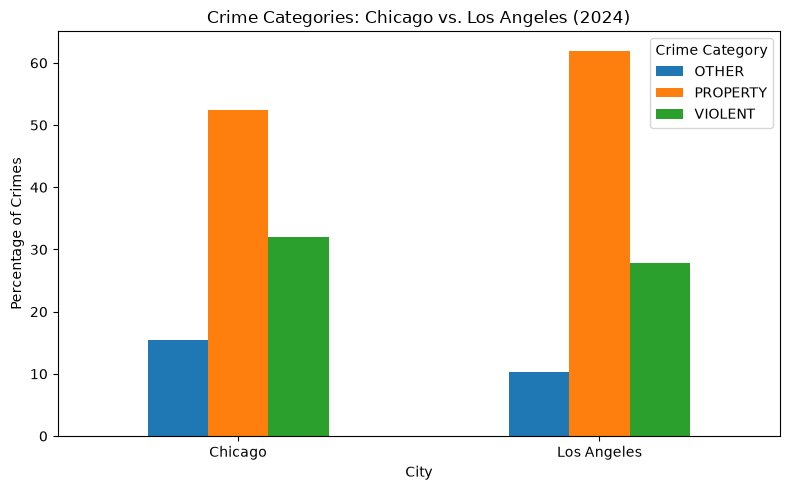

In [35]:
#visualization of crime numbers per category
crime_percent.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Crime Categories: Chicago vs. Los Angeles (2024)")
plt.xlabel("City")
plt.ylabel("Percentage of Crimes")
plt.xticks(rotation=0)
plt.legend(title="Crime Category")
plt.tight_layout()
plt.show()

In [36]:
#comparison of time periods
time_crime = (
    pd.crosstab(
        [crime_data["city"], crime_data["crime_category"]],
        crime_data["time_period"],
        normalize="index"
    ) * 100
).round(2)

time_crime



time_period                 AFTERNOON  EVENING  MORNING  NIGHT
city        crime_category                                    
Chicago     OTHER               31.47    30.63    21.16  16.73
            PROPERTY            31.65    26.90    20.85  20.61
            VIOLENT             30.22    29.80    19.92  20.05
Los Angeles OTHER               31.80    25.02    30.26  12.92
            PROPERTY            32.65    32.13    19.80  15.43
            VIOLENT             30.87    31.39    20.73  17.01

In [37]:
location_percent = (
    pd.crosstab(
        crime_data["city"],
        crime_data["location_category"],
        normalize="index"
    ) * 100
).round(2)

location_percent

location_category,COMMERCIAL,OTHER,PUBLIC,RESIDENTIAL
city,,,,
Chicago,15.71,5.06,44.63,34.6
Los Angeles,12.11,4.23,53.77,29.9


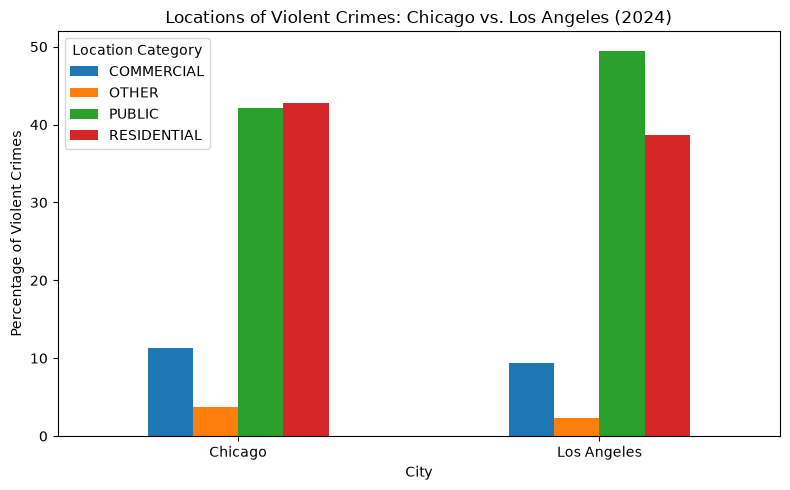

In [38]:
#select violent crime cases
violent_data = crime_data[ crime_data["crime_category"] == "VIOLENT"].copy()

#percentage distribution of violent crime by location
violent_location_percent = (
    pd.crosstab(
        violent_data["city"],
        violent_data["location_category"],
        normalize="index"
    ) * 100
).round(2)

violent_location_percent

violent_location_percent.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Locations of Violent Crimes: Chicago vs. Los Angeles (2024)")
plt.xlabel("City")
plt.ylabel("Percentage of Violent Crimes")
plt.xticks(rotation=0)
plt.legend(title="Location Category")
plt.tight_layout()
plt.show()

In [39]:
violent_location = (
    pd.crosstab(
        violent_data["city"],
        violent_data["location_category"],
        normalize="index"
    ) * 100
).round(2)

violent_location

location_category,COMMERCIAL,OTHER,PUBLIC,RESIDENTIAL
city,,,,
Chicago,11.30,3.76,42.13,42.81
Los Angeles,9.39,2.38,49.50,38.72


## Association Analysis

### Violent Crime

In [40]:
#preperation for association analysis
violent_assoc = pd.get_dummies(
    violent_data[["time_period", "location_category"]],
    prefix=["TIME", "LOC"]
)

violent_assoc.head()

,TIME_AFTERNOON,TIME_EVENING,TIME_MORNING,TIME_NIGHT,LOC_COMMERCIAL,LOC_OTHER,LOC_PUBLIC,LOC_RESIDENTIAL
0,False,False,False,True,False,False,True,False
1,False,False,False,True,False,False,True,False
4,False,False,False,True,False,False,False,True
8,False,False,False,True,False,False,True,False
9,False,True,False,False,False,False,False,True


In [41]:
#select violent crime in chicago
violent_assoc_chicago = violent_assoc.loc[violent_data["city"] == "Chicago"]

#generate frequent time-location itemsets
frequent_chicago = apriori(
    violent_assoc_chicago,
    min_support=0.03,
    use_colnames=True
)

frequent_chicago.sort_values(
    "support",
    ascending=False
).head(20)

,support,itemsets
7,0.428100,frozenset({LOC_RESIDENTIAL})
6,0.421292,frozenset({LOC_PUBLIC})
0,0.302205,frozenset({TIME_AFTERNOON})
1,0.298036,frozenset({TIME_EVENING})
3,0.200542,frozenset({TIME_NIGHT})
2,0.199217,frozenset({TIME_MORNING})
9,0.136197,"frozenset({TIME_AFTERNOON, LOC_PUBLIC})"
13,0.133643,"frozenset({TIME_EVENING, LOC_RESIDENTIAL})"
12,0.122015,"frozenset({LOC_PUBLIC, TIME_EVENING})"
4,0.113002,frozenset({LOC_COMMERCIAL})


In [42]:
#generate association rules for Chicago using Lift
rules_chicago = association_rules(
    frequent_chicago,
    metric="lift",
    min_threshold=0
)

rules_chicago[[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]].sort_values(
    "lift",
    ascending=False
).round(3)

,antecedents,consequents,support,confidence,lift
0,frozenset({TIME_AFTERNOON}),frozenset({LOC_COMMERCIAL}),0.040,0.133,1.175
1,frozenset({LOC_COMMERCIAL}),frozenset({TIME_AFTERNOON}),0.040,0.355,1.175
18,frozenset({TIME_NIGHT}),frozenset({LOC_RESIDENTIAL}),0.095,0.472,1.102
19,frozenset({LOC_RESIDENTIAL}),frozenset({TIME_NIGHT}),0.095,0.221,1.102
3,frozenset({LOC_PUBLIC}),frozenset({TIME_AFTERNOON}),0.136,0.323,1.070
2,frozenset({TIME_AFTERNOON}),frozenset({LOC_PUBLIC}),0.136,0.451,1.070
10,frozenset({TIME_EVENING}),frozenset({LOC_RESIDENTIAL}),0.134,0.448,1.047
11,frozenset({LOC_RESIDENTIAL}),frozenset({TIME_EVENING}),0.134,0.312,1.047
14,frozenset({TIME_MORNING}),frozenset({LOC_RESIDENTIAL}),0.088,0.441,1.030
15,frozenset({LOC_RESIDENTIAL}),frozenset({TIME_MORNING}),0.088,0.205,1.030


In [43]:
#keep only rules where a time period leads to a location category
rules_chicago_clean = rules_chicago[
    rules_chicago["antecedents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("TIME_")
    )
    &
    rules_chicago["consequents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("LOC_")
    )
][[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]].sort_values("lift", ascending=False).round(3)

rules_chicago_clean

,antecedents,consequents,support,confidence,lift
0,frozenset({TIME_AFTERNOON}),frozenset({LOC_COMMERCIAL}),0.040,0.133,1.175
18,frozenset({TIME_NIGHT}),frozenset({LOC_RESIDENTIAL}),0.095,0.472,1.102
2,frozenset({TIME_AFTERNOON}),frozenset({LOC_PUBLIC}),0.136,0.451,1.070
10,frozenset({TIME_EVENING}),frozenset({LOC_RESIDENTIAL}),0.134,0.448,1.047
14,frozenset({TIME_MORNING}),frozenset({LOC_RESIDENTIAL}),0.088,0.441,1.030
16,frozenset({TIME_NIGHT}),frozenset({LOC_PUBLIC}),0.084,0.419,0.994
9,frozenset({TIME_EVENING}),frozenset({LOC_PUBLIC}),0.122,0.409,0.972
7,frozenset({TIME_EVENING}),frozenset({LOC_COMMERCIAL}),0.033,0.110,0.969
12,frozenset({TIME_MORNING}),frozenset({LOC_PUBLIC}),0.079,0.397,0.942
4,frozenset({TIME_AFTERNOON}),frozenset({LOC_RESIDENTIAL}),0.112,0.371,0.866


In [44]:
#select violent crime from los angeles
violent_assoc_la = violent_assoc.loc[violent_data["city"] == "Los Angeles"]

#generate frequent time-location itemsets
frequent_la = apriori(
    violent_assoc_la,
    min_support=0.03,
    use_colnames=True
)

frequent_la.sort_values(
    "support",
    ascending=False
).head(20)

,support,itemsets
5,0.495031,frozenset({LOC_PUBLIC})
6,0.387242,frozenset({LOC_RESIDENTIAL})
1,0.313922,frozenset({TIME_EVENING})
0,0.308672,frozenset({TIME_AFTERNOON})
2,0.207288,frozenset({TIME_MORNING})
3,0.170118,frozenset({TIME_NIGHT})
8,0.164835,"frozenset({TIME_AFTERNOON, LOC_PUBLIC})"
10,0.150939,"frozenset({LOC_PUBLIC, TIME_EVENING})"
11,0.126544,"frozenset({TIME_EVENING, LOC_RESIDENTIAL})"
9,0.103763,"frozenset({TIME_AFTERNOON, LOC_RESIDENTIAL})"


In [45]:
#generate association rules for Los Angeles using lift
rules_la = association_rules(
    frequent_la,
    metric="lift",
    min_threshold=0
)

#keep only rules where a time period leads to a location category
rules_la_clean = rules_la[
    rules_la["antecedents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("TIME_")
    )
    &
    rules_la["consequents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("LOC_")
    )
][[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]].sort_values("lift", ascending=False).round(3)

rules_la_clean

,antecedents,consequents,support,confidence,lift
0,frozenset({TIME_AFTERNOON}),frozenset({LOC_COMMERCIAL}),0.033,0.107,1.138
16,frozenset({TIME_NIGHT}),frozenset({LOC_RESIDENTIAL}),0.074,0.438,1.131
2,frozenset({TIME_AFTERNOON}),frozenset({LOC_PUBLIC}),0.165,0.534,1.079
8,frozenset({TIME_EVENING}),frozenset({LOC_RESIDENTIAL}),0.127,0.403,1.041
12,frozenset({TIME_MORNING}),frozenset({LOC_RESIDENTIAL}),0.082,0.398,1.027
10,frozenset({TIME_MORNING}),frozenset({LOC_PUBLIC}),0.100,0.484,0.978
7,frozenset({TIME_EVENING}),frozenset({LOC_PUBLIC}),0.151,0.481,0.971
14,frozenset({TIME_NIGHT}),frozenset({LOC_PUBLIC}),0.079,0.464,0.937
4,frozenset({TIME_AFTERNOON}),frozenset({LOC_RESIDENTIAL}),0.104,0.336,0.868


In [46]:
#create readable rule names
def create_rule_name(row):
    time = next(iter(row["antecedents"])).replace("TIME_", "")
    location = next(iter(row["consequents"])).replace("LOC_", "")
    return time + " → " + location

rules_chicago_clean["rule"] = rules_chicago_clean.apply(
    create_rule_name, axis=1
)

rules_la_clean["rule"] = rules_la_clean.apply(
    create_rule_name, axis=1
)
comparison = pd.merge(
    rules_chicago_clean[["rule", "support", "confidence", "lift"]],
    rules_la_clean[["rule", "support", "confidence", "lift"]],
    on="rule",
    suffixes=("_Chicago", "_LA")
)

comparison

,rule,support_Chicago,confidence_Chicago,lift_Chicago,support_LA,confidence_LA,lift_LA
0,AFTERNOON → COMMERCIAL,0.040,0.133,1.175,0.033,0.107,1.138
1,NIGHT → RESIDENTIAL,0.095,0.472,1.102,0.074,0.438,1.131
2,AFTERNOON → PUBLIC,0.136,0.451,1.070,0.165,0.534,1.079
3,EVENING → RESIDENTIAL,0.134,0.448,1.047,0.127,0.403,1.041
4,MORNING → RESIDENTIAL,0.088,0.441,1.030,0.082,0.398,1.027
5,NIGHT → PUBLIC,0.084,0.419,0.994,0.079,0.464,0.937
6,EVENING → PUBLIC,0.122,0.409,0.972,0.151,0.481,0.971
7,MORNING → PUBLIC,0.079,0.397,0.942,0.100,0.484,0.978
8,AFTERNOON → RESIDENTIAL,0.112,0.371,0.866,0.104,0.336,0.868


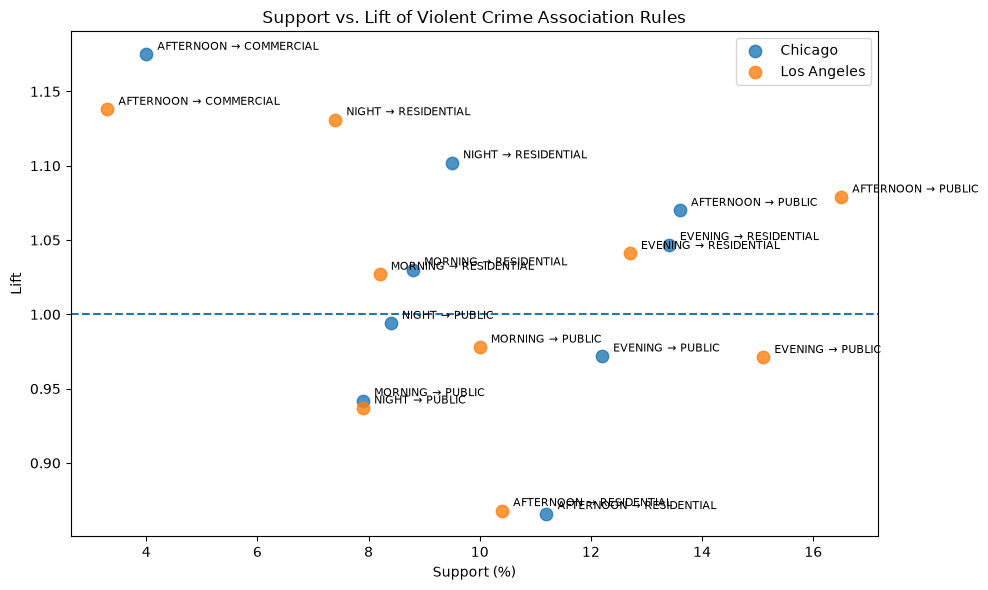

In [47]:
#prepare support and lift values chicago
plot_chicago = comparison[["rule", "support_Chicago", "lift_Chicago"]].copy()
plot_chicago["city"] = "Chicago"
plot_chicago = plot_chicago.rename(
    columns={
        "support_Chicago": "support",
        "lift_Chicago": "lift"
    }
)

#prepare suppoer and lift values la
plot_la = comparison[["rule", "support_LA", "lift_LA"]].copy()
plot_la["city"] = "Los Angeles"
plot_la = plot_la.rename(
    columns={
        "support_LA": "support",
        "lift_LA": "lift"
    }
)

#combine both into one data frame
plot_data = pd.concat([plot_chicago, plot_la], ignore_index=True)

plt.figure(figsize=(10, 6))

for city in plot_data["city"].unique():
    subset = plot_data[plot_data["city"] == city]
    plt.scatter(
        subset["support"] * 100,
        subset["lift"],
        label=city,
        s=80,
        alpha=0.8
    )

    for _, row in subset.iterrows():
        plt.text(
            row["support"] * 100 + 0.2,
            row["lift"] + 0.003,
            row["rule"],
            fontsize=8
        )

plt.axhline(y=1, linestyle="--")
plt.xlabel("Support (%)")
plt.ylabel("Lift")
plt.title("Support vs. Lift of Violent Crime Association Rules")
plt.legend()
plt.tight_layout()
plt.show()



### Property Crimes

In [48]:
#Filtering for Property 
property_data = crime_data[crime_data["crime_category"] == "PROPERTY"].copy()

property_assoc = pd.get_dummies(
    property_data[["time_period", "location_category"]],
    prefix=["TIME", "LOC"]
)

In [49]:
#Only Property Crime in Chicago
property_assoc_chicago = property_assoc.loc[property_data["city"] == "Chicago"]

frequent_property_chicago = apriori(
    property_assoc_chicago,
    min_support=0.03,
    use_colnames=True
)

rules_property_chicago = association_rules(
    frequent_property_chicago,
    metric="lift",
    min_threshold=0
)

In [50]:
#label rules
rules_property_chicago_clean = rules_property_chicago[
    rules_property_chicago["antecedents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("TIME_")
    )
    &
    rules_property_chicago["consequents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("LOC_")
    )
][[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]].sort_values("lift", ascending=False).round(3)

rules_property_chicago_clean

,antecedents,consequents,support,confidence,lift
0,frozenset({TIME_AFTERNOON}),frozenset({LOC_COMMERCIAL}),0.082,0.261,1.260
9,frozenset({TIME_EVENING}),frozenset({LOC_PUBLIC}),0.147,0.545,1.230
16,frozenset({TIME_MORNING}),frozenset({LOC_RESIDENTIAL}),0.068,0.324,1.113
20,frozenset({TIME_NIGHT}),frozenset({LOC_PUBLIC}),0.098,0.476,1.074
4,frozenset({TIME_AFTERNOON}),frozenset({LOC_RESIDENTIAL}),0.098,0.309,1.060
22,frozenset({TIME_NIGHT}),frozenset({LOC_RESIDENTIAL}),0.063,0.308,1.057
12,frozenset({TIME_MORNING}),frozenset({LOC_COMMERCIAL}),0.043,0.208,1.003
14,frozenset({TIME_MORNING}),frozenset({LOC_PUBLIC}),0.083,0.400,0.904
7,frozenset({TIME_EVENING}),frozenset({LOC_COMMERCIAL}),0.048,0.177,0.854
2,frozenset({TIME_AFTERNOON}),frozenset({LOC_PUBLIC}),0.115,0.363,0.819


In [51]:
#Only Property Crime in Los Angeles
property_assoc_la = property_assoc.loc[property_data["city"] == "Los Angeles"]


frequent_property_la = apriori(
    property_assoc_la,
    min_support=0.03,
    use_colnames=True
)

rules_property_la = association_rules(
    frequent_property_la,
    metric="lift",
    min_threshold=0
)

#Only TIME -> LOCATION rules
rules_property_la_clean = rules_property_la[
    rules_property_la["antecedents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("TIME_")
    )
    &
    rules_property_la["consequents"].apply(
        lambda x: len(x) == 1 and next(iter(x)).startswith("LOC_")
    )
][[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]].sort_values("lift", ascending=False).round(3)

#rules for label
rules_property_chicago_clean["rule"] = (
    rules_property_chicago_clean["antecedents"].apply(
        lambda x: next(iter(x)).replace("TIME_", "")
    )
    + " → "
    + rules_property_chicago_clean["consequents"].apply(
        lambda x: next(iter(x)).replace("LOC_", "")
    )
)

#rules for labels
rules_property_la_clean["rule"] = (
    rules_property_la_clean["antecedents"].apply(
        lambda x: next(iter(x)).replace("TIME_", "")
    )
    + " → "
    + rules_property_la_clean["consequents"].apply(
        lambda x: next(iter(x)).replace("LOC_", "")
    )
)

#combining chicago and los angeles 
property_comparison = pd.merge(
    rules_property_chicago_clean[
        ["rule", "support", "confidence", "lift"]
    ],
    rules_property_la_clean[
        ["rule", "support", "confidence", "lift"]
    ],
    on="rule",
    suffixes=("_Chicago", "_LA")
)

property_comparison

,rule,support_Chicago,confidence_Chicago,lift_Chicago,support_LA,confidence_LA,lift_LA
0,AFTERNOON → COMMERCIAL,0.082,0.261,1.260,0.057,0.176,1.206
1,EVENING → PUBLIC,0.147,0.545,1.230,0.198,0.615,1.131
2,MORNING → RESIDENTIAL,0.068,0.324,1.113,0.062,0.315,1.210
3,NIGHT → PUBLIC,0.098,0.476,1.074,0.086,0.555,1.022
4,AFTERNOON → RESIDENTIAL,0.098,0.309,1.060,0.091,0.280,1.077
5,NIGHT → RESIDENTIAL,0.063,0.308,1.057,0.038,0.244,0.939
6,MORNING → PUBLIC,0.083,0.400,0.904,0.100,0.503,0.925
7,EVENING → COMMERCIAL,0.048,0.177,0.854,0.040,0.123,0.843
8,AFTERNOON → PUBLIC,0.115,0.363,0.819,0.161,0.492,0.906
9,EVENING → RESIDENTIAL,0.062,0.232,0.798,0.069,0.214,0.821


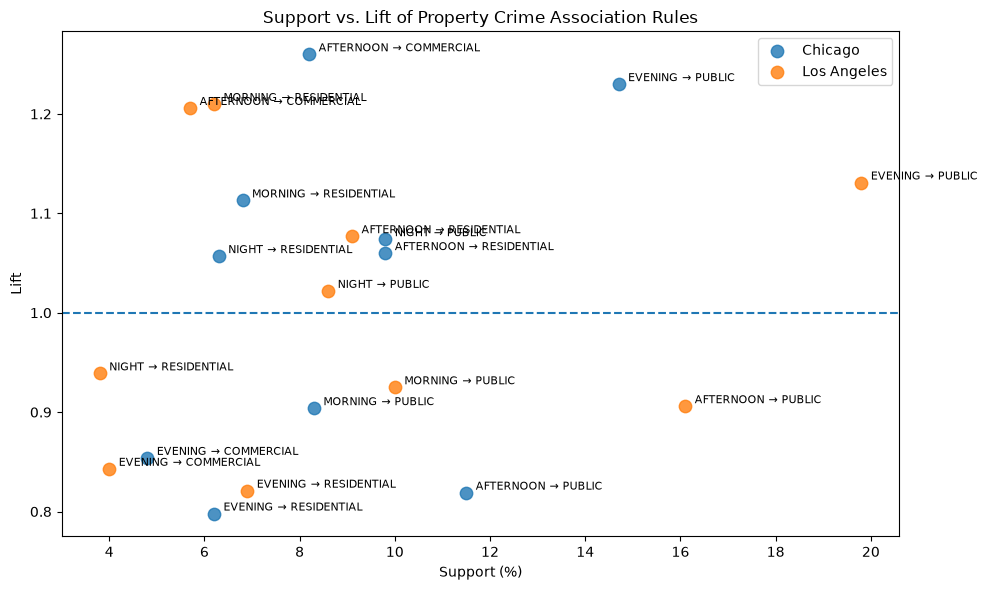

In [52]:
#data for the plot
plot_chicago = property_comparison[
    ["rule", "support_Chicago", "lift_Chicago"]
].copy()

plot_chicago["city"] = "Chicago"

plot_chicago = plot_chicago.rename(
    columns={
        "support_Chicago": "support",
        "lift_Chicago": "lift"
    }
)

plot_la = property_comparison[
    ["rule", "support_LA", "lift_LA"]
].copy()

plot_la["city"] = "Los Angeles"

plot_la = plot_la.rename(
    columns={
        "support_LA": "support",
        "lift_LA": "lift"
    }
)

plot_property = pd.concat(
    [plot_chicago, plot_la],
    ignore_index=True
)

#Scatterplot
plt.figure(figsize=(10, 6))

for city in plot_property["city"].unique():
    subset = plot_property[
        plot_property["city"] == city
    ]

    plt.scatter(
        subset["support"] * 100,
        subset["lift"],
        label=city,
        s=80,
        alpha=0.8
    )

    #labeling 
    for _, row in subset.iterrows():
        plt.text(
            row["support"] * 100 + 0.2,
            row["lift"] + 0.003,
            row["rule"],
            fontsize=8
        )

#reference line = 1
plt.axhline(
    y=1,
    linestyle="--"
)

plt.title("Support vs. Lift of Property Crime Association Rules")
plt.xlabel("Support (%)")
plt.ylabel("Lift")
plt.legend()
plt.tight_layout()
plt.show()

## Comparison of Violent and Property Crime

In [53]:
violent_property_comparison = pd.merge(
    comparison[
        [
            "rule",
            "support_Chicago",
            "lift_Chicago",
            "support_LA",
            "lift_LA"
        ]
    ],
    property_comparison[
        [
            "rule",
            "support_Chicago",
            "lift_Chicago",
            "support_LA",
            "lift_LA"
        ]
    ],
    on="rule",
    suffixes=("_Violent", "_Property")
).round(3)

violent_property_comparison

,rule,support_Chicago_Violent,lift_Chicago_Violent,support_LA_Violent,lift_LA_Violent,support_Chicago_Property,lift_Chicago_Property,support_LA_Property,lift_LA_Property
0,AFTERNOON → COMMERCIAL,0.040,1.175,0.033,1.138,0.082,1.260,0.057,1.206
1,NIGHT → RESIDENTIAL,0.095,1.102,0.074,1.131,0.063,1.057,0.038,0.939
2,AFTERNOON → PUBLIC,0.136,1.070,0.165,1.079,0.115,0.819,0.161,0.906
3,EVENING → RESIDENTIAL,0.134,1.047,0.127,1.041,0.062,0.798,0.069,0.821
4,MORNING → RESIDENTIAL,0.088,1.030,0.082,1.027,0.068,1.113,0.062,1.210
5,NIGHT → PUBLIC,0.084,0.994,0.079,0.937,0.098,1.074,0.086,1.022
6,EVENING → PUBLIC,0.122,0.972,0.151,0.971,0.147,1.230,0.198,1.131
7,MORNING → PUBLIC,0.079,0.942,0.100,0.978,0.083,0.904,0.100,0.925
8,AFTERNOON → RESIDENTIAL,0.112,0.866,0.104,0.868,0.098,1.060,0.091,1.077


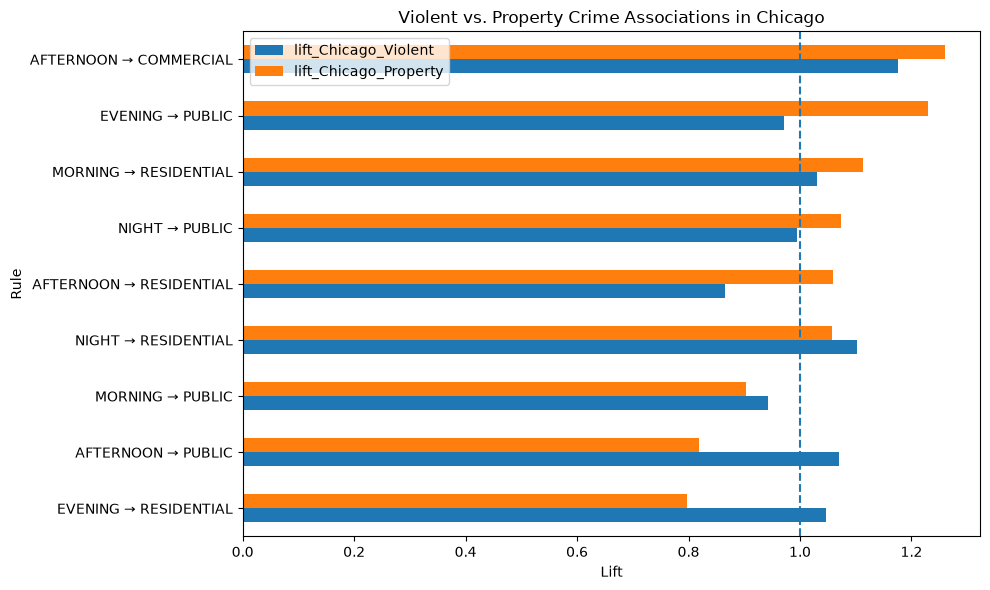

In [54]:
#Violet and Property Crime Comparison Chicago
vp_chicago = violent_property_comparison.set_index("rule")[
    ["lift_Chicago_Violent", "lift_Chicago_Property"]
]

vp_chicago = vp_chicago.sort_values("lift_Chicago_Property")

vp_chicago.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.axvline(x=1, linestyle="--")
plt.title("Violent vs. Property Crime Associations in Chicago")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()

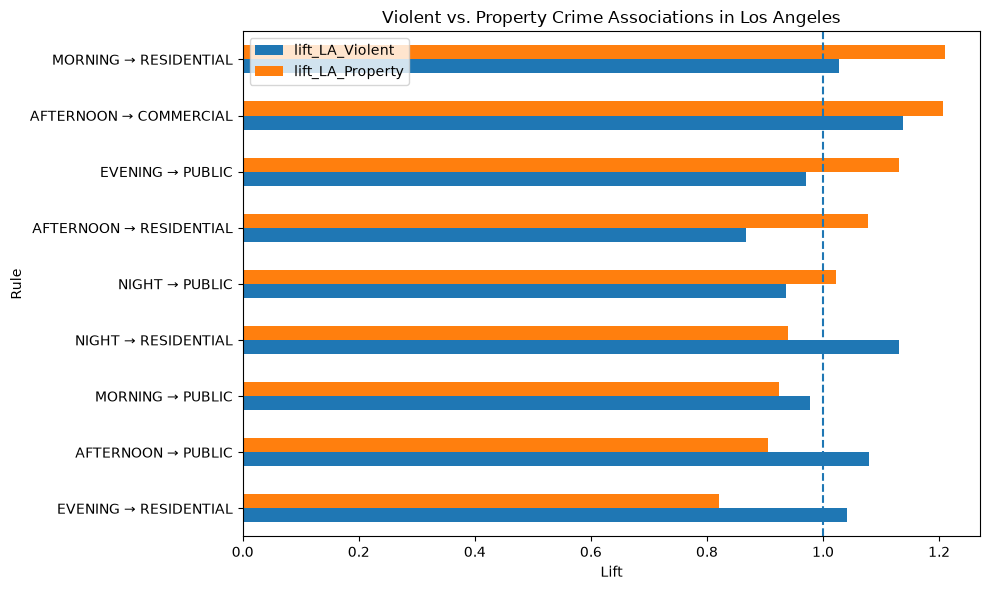

In [55]:
#Violet and Property Crime Comparison Los Angeles
vp_la = violent_property_comparison.set_index("rule")[
    ["lift_LA_Violent", "lift_LA_Property"]
]

vp_la = vp_la.sort_values("lift_LA_Property")

vp_la.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.axvline(x=1, linestyle="--")
plt.title("Violent vs. Property Crime Associations in Los Angeles")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()


##  Hypothesis Evaluation

Grundlegend wird die Hypothese durch die herausgearbeiteten Muster unterstützt

Die Analyse zeigt, dass Tatzeit und Tatort nicht unabhängig voneinander auftreten. Sowohl bei Violent als auch bei Property Crime konnten Zeit-Ort-Kombinationen mit Lift-Werten über 1 festgestellt werden.

Dabei gibt es unterschiedliche Muster zwischen den beiden Deliktkategorien. Bei Property Crime zeigt sich insbesondere eine positive Assoziation zwischen EVENING und PUBLIC, bei Violent Crime NIGHT und RESIDENTIAL.

Auch zwischen Chicago und Los Angeles unterscheiden sich einzelne Assoziationen in ihrer Stärke, obwohl viele grundlegende Muster in beiden Städten ähnlich sind.

Die Ergebnisse unterstützen damit die Annahme, dass sich Zeit-Ort-Muster zwischen Violent und Property Crime unterscheiden und dass die Stärke einzelner Assoziationen zwischen Chicago und Los Angeles variiert.